# BIL545 · Proje 1
## 9.5 Online alışverişte satın alma niyeti

| | |
|---|---|
| Ders | Veri Madenciliğinde İleri Konular · 2026–2027 Güz |
| Öğrenci | Emircan Demir · 264309006 |
| Grup | Grup 7 |
| GitHub | [Proje deposu](https://github.com/EmircanDemirTR/bil545-online-alisveris) |

Grup dağıldıktan sonra hoca mailde sadece Bölüm 2'yi yapmam gerektiğini söyledi. Bölüm 1'i de ben ekledim.

**Araştırma sorusu.** Oturumda hangi sayfalara bakıldığı ve bu sayfalarda ne kadar kalındığı, satın almayla biten oturumları ayırmaya yardımcı oluyor mu? Elimde oturumun tamamına ait özetler var. Bu yüzden ziyaret sürerken ne kadar erken tahmin yapabileceğimi bu veriyle ölçemiyorum.

## Hazırlık

Colab'da defteri açtıktan sonra **Çalışma zamanı → Tümünü çalıştır** seçeneğini kullanın.

In [1]:
import hashlib
import io
import sys
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import threadpoolctl
from IPython.display import display

SEED = 42
np.random.seed(SEED)
print("Python", sys.version.split()[0])
for library in (np, pd, sklearn, matplotlib, scipy, joblib, threadpoolctl):
    print(library.__name__, library.__version__)

Python 3.12.10
numpy 2.5.3
pandas 3.0.6
sklearn 1.9.1
matplotlib 3.11.2
scipy 1.18.1
joblib 1.6.0
threadpoolctl 3.7.0


### Veriyi yükleme

Defter CSV'yi çalışma klasöründe veya bir üst klasörde arıyor. Bulamazsa UCI'dan indiriyor. Hücre, kullanılan dosyanın SHA-256 özetini gösteriyor.

[UCI veri seti](https://doi.org/10.24432/C5F88Q) · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

In [2]:
FILENAME = "online_shoppers_intention.csv"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
paths = (Path(FILENAME), Path("..") / FILENAME)
local_csv = next((path for path in paths if path.is_file()), None)

if local_csv is None:
    with urlopen(UCI_ZIP, timeout=45) as response:
        with ZipFile(io.BytesIO(response.read())) as archive:
            csv_bytes = archive.read(FILENAME)
else:
    csv_bytes = local_csv.read_bytes()

print("Girdi:", "UCI arşivi" if local_csv is None else local_csv)
print("SHA-256:", hashlib.sha256(csv_bytes).hexdigest())

Girdi: UCI arşivi
SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


# Bölüm 1 · Veri, ön işleme ve sızıntı

**Okuma notu.** Kaufman vd.'ye göre modelin tahmin anında elinde olmayacak hedef bilgisi, doğrudan ya da dolaylı biçimde öğrenmeye girerse sızıntı olur. Neyin sızıntı sayıldığını anlamak için önce tahminin amacı ve zamanı belirlenir. Yazarlar, ön işleme dâhil öğrenmeye giden veriyi, modelin tahmin için göreceği veriden ayırmayı öneriyor. Beklenmedik kadar iyi bir skor veya tek bir sütunun şaşırtıcı gücü ise o bilginin nereden geldiğini araştırmak için bir işaret. [Kaufman vd. (2012)](https://doi.org/10.1145/2382577.2382579)

Bu defterde *PageValues* eklenince AP'nin 0,3288'den 0,6412'ye çıkması böyle bir işaret. Sütunun nasıl hesaplandığına 1.5'te baktım.

### 1.1 Veri künyesi

| Soru | Cevap |
|---|---|
| Veri nereden geliyor? | Sakar vd. bu veriyi bir e-ticaret sitesindeki satın alma ve siteyi terk etme davranışını incelemek için kullandı. Sakar ve Kastro tabloyu UCI'da yayımladı. |
| Hangi dönem? | UCI bir yıl içindeki farklı kullanıcılardan alınan oturumları bildiriyor. CSV'de yalnızca ay adı var. 2018, UCI'da yayımlandığı yıl. |
| Hedef ne? | *Revenue*, oturumda bir satın alma olup olmadığını gösteriyor. Niyeti doğrudan ölçmüyor. Alışveriş yapmayı düşünüp siteden çıkan biri de negatif sınıfa giriyor. |
| Kimler az temsil ediliyor olabilir? | Veri tek mağazadan. Bazı aylar ve trafik türleri az görülüyor. Yaş ve gelir bilgisi olmadığı için bu grupları karşılaştıramıyorum. |
| Lisans | CC BY 4.0 |

In [3]:
df_raw = pd.read_csv(io.BytesIO(csv_bytes), na_values=["?"])
calendar = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = (
    df_raw.groupby("Month")["Revenue"].agg(["size", "sum", "mean"])
    .reindex(calendar)
    .rename(columns={"size": "Oturum", "sum": "Satın alma", "mean": "Satın alma oranı"})
)
display(by_month.style.format(
    {"Oturum": "{:.0f}", "Satın alma": "{:.0f}", "Satın alma oranı": "{:.2%}"},
    na_rep="—",
))

,Oturum,Satın alma,Satın alma oranı
Month,,,
Jan,—,—,—
Feb,184,3,1.63%
Mar,1907,192,10.07%
Apr,—,—,—
May,3364,365,10.85%
June,288,29,10.07%
Jul,432,66,15.28%
Aug,433,76,17.55%
Sep,448,86,19.20%


**Yorum.** Ocak ve nisanda kayıt yok. Oturumların yaklaşık yarısı mayıs ve kasımdan geliyor. Elimde tam tarih ve kampanya bilgisi olmadığı için farkın mevsimden kaynaklanıp kaynaklanmadığını söyleyemiyorum.

### 1.2 Keşifsel analiz

Tabloda sütunun dosyada nasıl saklandığıyla neyi ifade ettiğini ayrı gösterdim. Örneğin tarayıcı kodu sayı olarak saklanıyor ama bir kategori.

Negatif sayısal değer sayısı: 0
Ham tablo: 12.330 satır × 18 sütun


,Saklama,Ölçek,Eksik (%),Farklı değer,En küçük,Sıfır (%)
Sütun,,,,,,
Administrative,int64,Oran · sayım,"0,00",27,0,"46,78"
Administrative_Duration,float64,Oran · süre,"0,00",3335,0,"47,88"
Informational,int64,Oran · sayım,"0,00",17,0,"78,66"
Informational_Duration,float64,Oran · süre,"0,00",1258,0,"80,49"
ProductRelated,int64,Oran · sayım,"0,00",311,0,"0,31"
ProductRelated_Duration,float64,Oran · süre,"0,00",9551,0,"6,12"
BounceRates,float64,Oran · pay,"0,00",1872,0,"44,75"
ExitRates,float64,Oran · pay,"0,00",4777,0,"0,62"
PageValues,float64,Oran · metrik değer,"0,00",2704,0,"77,86"


Tam tekrar sayısı (ilk satır hariç): 125
Tekrar grubunda olan satır sayısı: 201
Bu gruplarda tek ürün sayfası, süre 0 ve satın alma yok: 189


,Oturum,Oran (%)
Satın alma yok,10.422,"84,53"
Satın alma var,1.908,"15,47"


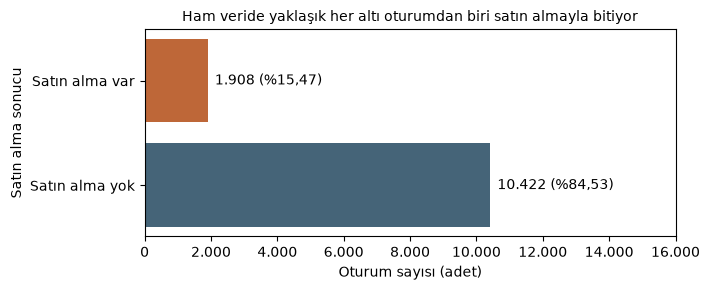

In [4]:
page_counts = ["Administrative", "Informational", "ProductRelated"]
durations = [f"{column}_Duration" for column in page_counts]
rate_columns = ["BounceRates", "ExitRates"]
nominal = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
target = "Revenue"
categorical = nominal + ["Weekend"]
numeric = page_counts + durations + ["SpecialDay"] + rate_columns
features = numeric + categorical
scale = {
    **dict.fromkeys(page_counts, "Oran · sayım"),
    **dict.fromkeys(durations, "Oran · süre"),
    "BounceRates": "Oran · pay",
    "ExitRates": "Oran · pay",
    "PageValues": "Oran · metrik değer",
    "SpecialDay": "Sıralı · yakınlık puanı",
    **dict.fromkeys(nominal, "Nominal kategori"),
    "Weekend": "İkili kategori",
    "Revenue": "İkili hedef",
}
assert set(df_raw.columns) == set(scale)
assert df_raw[target].isin([True, False]).all()
negative_count = int(df_raw.select_dtypes(include="number").lt(0).sum().sum())
print("Negatif sayısal değer sayısı:", negative_count)

def audit_table(frame):
    quantitative = numeric + ["PageValues"]
    rows = []
    for name, values in frame.items():
        rows.append({
            "Sütun": name,
            "Saklama": str(values.dtype),
            "Ölçek": scale[name],
            "Eksik (%)": 100 * values.isna().mean(),
            "Farklı değer": values.nunique(),
            "En küçük": values.min() if name in quantitative else np.nan,
            "Sıfır (%)": 100 * values.eq(0).mean() if name in quantitative else np.nan,
        })
    return pd.DataFrame(rows).set_index("Sütun")

row_count = f"{len(df_raw):,}".replace(",", ".")
print(f"Ham tablo: {row_count} satır × {df_raw.shape[1]} sütun")
display(audit_table(df_raw).style.format(
    {"Eksik (%)": "{:.2f}", "Sıfır (%)": "{:.2f}", "En küçük": "{:g}"},
    na_rep="—", decimal=","
))

duplicates = df_raw.duplicated(keep=False)
single_product = df_raw["ProductRelated"].eq(1) & df_raw["ProductRelated_Duration"].eq(0)
no_purchase = df_raw[target].eq(False)
print("Tam tekrar sayısı (ilk satır hariç):", df_raw.duplicated().sum())
print("Tekrar grubunda olan satır sayısı:", duplicates.sum())
print("Bu gruplarda tek ürün sayfası, süre 0 ve satın alma yok:",
      (duplicates & single_product & no_purchase).sum())

X = df_raw[features].copy()
y = df_raw[target].astype(int)
assert len(X) == len(df_raw) and "PageValues" not in X and target not in X

class_counts = y.value_counts().reindex([0, 1]).to_frame("Oturum")
class_counts.index = ["Satın alma yok", "Satın alma var"]
class_counts["Oran (%)"] = 100 * class_counts["Oturum"] / len(y)
display(class_counts.style.format({"Oran (%)": "{:.2f}"}, thousands=".", decimal=","))

fig, ax = plt.subplots(figsize=(7.2, 3))
bars = ax.barh(class_counts.index, class_counts["Oturum"], color=["#456478", "#be6738"])
counts = [f"{count:,}".replace(",", ".") for count in class_counts["Oturum"]]
percentages = [f"%{pct:.2f}".replace(".", ",") for pct in class_counts["Oran (%)"]]
ax.bar_label(bars, labels=[f"{count} ({pct})" for count, pct in zip(counts, percentages)],
             padding=5)
ax.set(xlabel="Oturum sayısı (adet)", ylabel="Satın alma sonucu", xlim=(0, 16000))
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}".replace(",", "."))
ax.set_title("Ham veride yaklaşık her altı oturumdan biri satın almayla bitiyor", fontsize=10)
plt.tight_layout()
plt.show()

**Yorum.** 12.330 oturumun %15,47'si satın almayla bitmiş. Birebir eşleşen satırlar 201 oturumu kapsıyor. Bunların 189'unda bir ürün sayfası, 0 süre ve satın alma yok. Aynı özet iki farklı ziyaretten de çıkabileceği için bütün satırları tuttum. UCI farklı kullanıcılardan birer oturum alındığını söylüyor. *Returning_Visitor* geçmişte ziyaret etmiş birini gösteriyor. CSV'de kullanıcı kimliği olmadığı için örneklemeyi kontrol edemiyorum ve kullanıcıya göre kat ayıramıyorum.

#### Şüpheli öznitelikler

| Neye baktım? | Ne yaptım? |
|---|---|
| Kimlik gibi görünenler | *OperatingSystems*, *Browser*, *Region* ve *TrafficType* kategori kodu. Kullanıcı veya oturum kimliği yok. |
| Eksik olabilecek kodlar | Boş hücre veya −1 gibi negatif bir kod çıkmadı. Sayfa görüldüğü hâlde süresi 0 olan satırlara 1.3'te baktım. |
| Sonradan bilinebilecek değerler | *Revenue* hedef. İşlem değerini içerebilen *PageValues* ana modelden çıktı. Sayfa sayıları ve süreler tamamlanmış oturumun özeti. |

*BounceRates* ve *ExitRates* sayfa düzeyinde gezinme oranları. Katırcıoğlu'nun tezinde ziyaret edilen sayfalar üzerinden kullanılıyor. Satın alma tutarını girdi olarak almadıkları için oturum sonu modelinde ikisini de tuttum. CSV'de oranların hesaplandığı tarihler yok. [Katırcıoğlu (2018), s. 18 ve 32](https://acikerisim.bahcesehir.edu.tr/server/api/core/bitstreams/039f6b43-b844-41b8-a8e7-6b92ed5bdd39/content)

**Bölüm 2'de kullanacağım veri.** 12.330 satırın tamamı ve *PageValues* dışında kalan 16 öznitelik. Hedef *Revenue*. Süreleri CSV'deki gibi bıraktım.

### 1.3 Eksiklik analizi

CSV'de boş hücre ya da açık bir eksik kodu çıkmadı. Sayfa sayısı pozitifken süresi 0 olan satırları ayrıca inceledim.

Aday eksik işareti sayısı: 0
NaN'a dönüşen veya doğal olarak eksik hücre: 0


,"Sayfa yok, süre 0","Sayfa var, süre 0","BounceRates = 0,2",Toplam süre 0,Satın alma
Süre,,,,,
Administrative_Duration,5768,135,"10,37%","10,37%","25,19%"
Informational_Duration,9699,226,"2,65%","2,65%","21,24%"
ProductRelated_Duration,38,717,"95,26%","97,91%","0,98%"


,Oturum,Tek bilgi sayfası,Diğer süreler pozitif,Ort. ExitRates,Satın alma
Bilgi sayfası süresi,,,,,
Süre = 0,226,"96,02%","97,35%","0,039","21,24%"
Süre > 0,2.405,"34,26%","99,75%","0,023","23,49%"


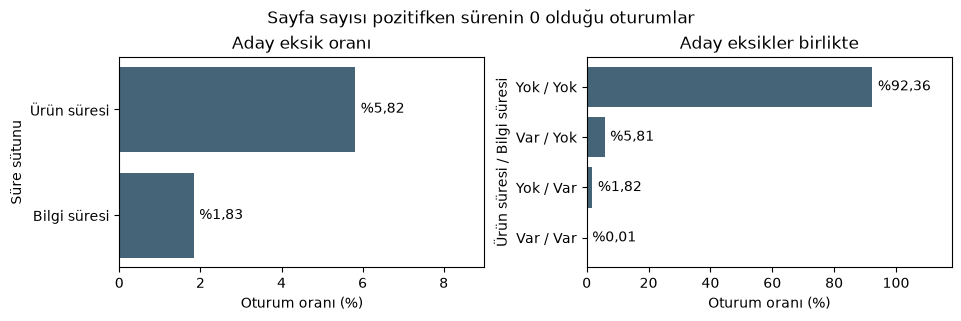

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

raw_tokens = pd.read_csv(io.BytesIO(csv_bytes), dtype=str, keep_default_na=False)
missing_tokens = {"", "?", "na", "n/a", "nan", "null"}
token_mask = raw_tokens.apply(lambda column: column.str.strip().str.lower().isin(missing_tokens))
print("Aday eksik işareti sayısı:", token_mask.sum().sum())
print("NaN'a dönüşen veya doğal olarak eksik hücre:", df_raw.isna().sum().sum())
zero_duration = pd.DataFrame({
    duration: df_raw[count].gt(0) & df_raw[duration].eq(0)
    for count, duration in zip(page_counts, durations)
})
zero_total = df_raw[durations].sum(axis=1).eq(0)
zero_audit = pd.DataFrame([
    {
        "Süre": duration,
        "Sayfa yok, süre 0": (df_raw[count].eq(0) & df_raw[duration].eq(0)).sum(),
        "Sayfa var, süre 0": mask.sum(),
        "BounceRates = 0,2": df_raw.loc[mask, "BounceRates"].eq(0.2).mean(),
        "Toplam süre 0": zero_total[mask].mean(),
        "Satın alma": y[mask].mean(),
    }
    for count, (duration, mask) in zip(page_counts, zero_duration.items())
]).set_index("Süre")
display(zero_audit.style.format(
    {name: "{:.2%}" for name in ["BounceRates = 0,2", "Toplam süre 0", "Satın alma"]},
    decimal=",",
))

info = df_raw.loc[df_raw["Informational"].gt(0)].copy()
info["Tek bilgi sayfası"] = info["Informational"].eq(1)
info["Diğer süreler pozitif"] = info[["Administrative_Duration", "ProductRelated_Duration"]].sum(axis=1).gt(0)
info_status = info["Informational_Duration"].eq(0).map({False: "Süre > 0", True: "Süre = 0"})
info_comparison = info.groupby(info_status, sort=False).agg(
    Oturum=("Revenue", "size"),
    **{"Tek bilgi sayfası": ("Tek bilgi sayfası", "mean"),
       "Diğer süreler pozitif": ("Diğer süreler pozitif", "mean"),
       "Ort. ExitRates": ("ExitRates", "mean"),
       "Satın alma": ("Revenue", "mean")},
)
info_comparison.index.name = "Bilgi sayfası süresi"
display(info_comparison.style.format(
    {"Tek bilgi sayfası": "{:.2%}", "Diğer süreler pozitif": "{:.2%}",
     "Ort. ExitRates": "{:.3f}", "Satın alma": "{:.2%}"},
    thousands=".", decimal=",",
))

candidate_columns = ["ProductRelated_Duration", "Informational_Duration"]
candidates = zero_duration[candidate_columns]
X_missing = X.copy()
X_missing[candidate_columns] = X[candidate_columns].mask(candidates)

status = candidates.replace({False: "Yok", True: "Var"})
order = [("Yok", "Yok"), ("Var", "Yok"), ("Yok", "Var"), ("Var", "Var")]
patterns = status.value_counts(normalize=True).reindex(order, fill_value=0).mul(100)
fig, (rates_ax, pattern_ax) = plt.subplots(1, 2, figsize=(9.5, 3.1), layout="constrained")
for ax, labels, values, limit in [
    (rates_ax, ["Ürün süresi", "Bilgi süresi"], candidates.mean().mul(100), 9),
    (pattern_ax, [" / ".join(pair) for pair in order], patterns, 118),
]:
    bars = ax.barh(labels, values, color="#456478")
    ax.bar_label(bars, [f"%{value:.2f}".replace(".", ",") for value in values], padding=4)
    ax.set_xlim(0, limit)
    ax.invert_yaxis()
rates_ax.set(title="Aday eksik oranı", xlabel="Oturum oranı (%)", ylabel="Süre sütunu")
pattern_ax.set(title="Aday eksikler birlikte", xlabel="Oturum oranı (%)",
               ylabel="Ürün süresi / Bilgi süresi")
fig.suptitle("Sayfa sayısı pozitifken sürenin 0 olduğu oturumlar")
plt.show()

outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
splits = list(outer_cv.split(X, y))
SCORING = {
    "AP": "average_precision",
    "ROC AUC": "roc_auc",
    "Dengeli doğruluk": "balanced_accuracy",
    "F1": "f1",
    "Duyarlılık": "recall",
}

def preprocessing(traffic_encoder=None, indicator=False, numeric_columns=numeric):
    num = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=indicator)),
        ("scale", StandardScaler()),
    ])
    if traffic_encoder is None:
        traffic_encoder = OneHotEncoder(handle_unknown="ignore")
    other_categories = [c for c in categorical if c != "TrafficType"]
    return ColumnTransformer([
        ("sayisal", num, numeric_columns),
        ("kategori", OneHotEncoder(handle_unknown="ignore"), other_categories),
        ("trafik", traffic_encoder, ["TrafficType"]),
    ])

def logistic(preprocessor):
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ])

def fold_scores(estimator, data, cv=splits):
    evaluated = cross_validate(estimator, data, y, cv=cv, scoring=SCORING, error_score="raise")
    return pd.DataFrame({name: evaluated[f"test_{name}"] for name in SCORING})

def score_summary(results):
    return pd.DataFrame({
        name: table.apply(lambda column: f"{column.mean():.4f} ± {column.std():.4f}")
        for name, table in results.items()
    }).T

def paired_ap(first, second):
    delta = second["AP"] - first["AP"]
    return f"{delta.mean():+.4f} ± {delta.std():.4f}"

In [6]:
onehot = logistic(preprocessing())
base_score = fold_scores(onehot, X)
missing_scores = {
    "Sıfırlar korundu": base_score,
    "Aday sıfırlar → NaN, medyan": fold_scores(onehot, X_missing),
    "Aday sıfırlar → NaN, medyan + gösterge": fold_scores(
        logistic(preprocessing(indicator=True)), X_missing
    ),
}
display(score_summary(missing_scores))
print("Eksik göstergesinin AP farkı:",
      paired_ap(missing_scores["Aday sıfırlar → NaN, medyan"],
                missing_scores["Aday sıfırlar → NaN, medyan + gösterge"]))

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Sıfırlar korundu,0.3288 ± 0.0145,0.7505 ± 0.0117,0.5119 ± 0.0047,0.0568 ± 0.0179,0.0304 ± 0.0099
"Aday sıfırlar → NaN, medyan",0.3289 ± 0.0146,0.7506 ± 0.0117,0.5118 ± 0.0047,0.0562 ± 0.0177,0.0301 ± 0.0098
"Aday sıfırlar → NaN, medyan + gösterge",0.3295 ± 0.0142,0.7514 ± 0.0116,0.5130 ± 0.0060,0.0610 ± 0.0221,0.0328 ± 0.0123


Eksik göstergesinin AP farkı: +0.0006 ± 0.0019


**Yorum.** Ürün sayfası olup süresi sıfır olan 717 oturumun %97,91'inde üç sürenin toplamı da sıfır. Bu oturumların %95,26'sında *BounceRates* 0,2 ve %77,13'ünde tek ürün sayfası var. Bu grupta satın alma oranı %0,98, tüm veride %15,47. Eski Google Analytics'te başka istek ya da etkinlik gelmezse süre sıfır kalabiliyor. Ürün grubundaki yığılma bununla uyumlu. *BounceRates* bir sayfa ortalaması olduğu için, her satırın tek istekle bittiğini söyleyemiyorum. [Google Analytics](https://support.google.com/analytics/answer/9264222?hl=en) · [EPA, Google Analytics ölçümleri](https://www.epa.gov/sites/production/files/documents/glossary_of_metrics_used_in_google_analytics.pdf)

Süresi sıfır olan 226 bilgi sayfası oturumunun %96,02'sinde bir bilgi sayfası var ve %97,35'inde başka sayfa türlerinde pozitif süre ölçülmüş. Ortalama *ExitRates* sıfır sürelilerde 0,039, pozitif sürelilerde 0,023. Satın alma oranları %21,24 ve %23,49. Bu desen, oturumda diğer süreler ölçülürken son bilgi sayfasının süresinin ölçülememesiyle uyumlu. CSV'de sayfa sırası olmadığı için hangisinin son sayfa olduğunu göremiyorum.

Bu sıfırları ölçüm kaybı sayarsam ürün süresi için tahminim **MAR**. Sıfırlar, hemen çıkma oranı 0,2 olan ve tek ürün sayfası görülen oturumlarda yoğunlaşıyor. Bu da MCAR varsayımını zayıflatıyor.

Bilgi süresi için de tahminim **MAR**, ama burada daha az eminim. *ExitRates* bir ipucu veriyor. Sayfa sırası veride yok ve gözlenen değişkenler hesaba katıldığında bile ölçüm kaybı gerçek süreye bağlıysa MNAR olabilir.

Ana modelde sıfırları korudum. Adayları *NaN* sayıp medyan ve gösterge kullanınca AP 0,3288'den 0,3295'e çıktı.

### 1.4 Kategorik kodlama

20 farklı değeri olan *TrafficType* sütununu seçtim. Bazı değerler yalnızca bir kere geçiyor. Karşılaştırmada sadece bu sütunun kodlamasını değiştirdim.

In [7]:
traffic_counts = X["TrafficType"].value_counts().sort_index()
display(traffic_counts.rename_axis("Trafik kodu").to_frame("Oturum sayısı").T)
print("20'den az gözlemli kategori sayısı:", traffic_counts.lt(20).sum())

def traffic_target_encoder():
    options = {"target_type": "binary", "smooth": 10}
    sklearn_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    if sklearn_version >= (1, 9):
        inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        return TargetEncoder(cv=inner_cv, **options)
    return TargetEncoder(cv=5, random_state=SEED, **options)

rare = logistic(preprocessing(
    traffic_encoder=OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist")
))
target_encoded = logistic(preprocessing(traffic_encoder=traffic_target_encoder()))

# Bilerek yanlış: doğrulama etiketleri kategori ortalamalarına giriyor.
traffic = X[["TrafficType"]]
global_traffic = traffic_target_encoder().fit(traffic, y).transform(traffic)
X_wrong_encoding = X.assign(TrafficType=global_traffic.ravel())
fixed_numeric_traffic = logistic(preprocessing(traffic_encoder="passthrough"))

encoding_scores = {
    "One-hot": base_score,
    "Nadirleri birleştiren one-hot": fold_scores(rare, X),
    "Kat dışı hedef kodlama": fold_scores(target_encoded, X),
    "Tüm etiketlerle hedef kodlama (yanlış)": fold_scores(fixed_numeric_traffic, X_wrong_encoding),
}
display(score_summary(encoding_scores))
print("Yanlış − kat dışı kodlama, eşleştirilmiş AP farkı:",
      paired_ap(encoding_scores["Kat dışı hedef kodlama"],
                encoding_scores["Tüm etiketlerle hedef kodlama (yanlış)"]))

Trafik kodu,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Oturum sayısı,2451,3913,2052,1069,260,444,40,343,42,450,247,1,738,13,38,3,1,10,17,198


20'den az gözlemli kategori sayısı: 6


,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
One-hot,0.3288 ± 0.0145,0.7505 ± 0.0117,0.5119 ± 0.0047,0.0568 ± 0.0179,0.0304 ± 0.0099
Nadirleri birleştiren one-hot,0.3291 ± 0.0145,0.7505 ± 0.0117,0.5119 ± 0.0047,0.0566 ± 0.0180,0.0303 ± 0.0100
Kat dışı hedef kodlama,0.3292 ± 0.0136,0.7509 ± 0.0120,0.5093 ± 0.0040,0.0461 ± 0.0155,0.0244 ± 0.0085
Tüm etiketlerle hedef kodlama (yanlış),0.3307 ± 0.0141,0.7519 ± 0.0118,0.5098 ± 0.0040,0.0478 ± 0.0155,0.0254 ± 0.0085


Yanlış − kat dışı kodlama, eşleştirilmiş AP farkı: +0.0015 ± 0.0013


**Yorum.** Eğitim katında 20'den az görülen trafik türlerini birleştirdim. Doğru hedef kodlamada bir eğitim satırının kodu kendi etiketinden hesaplanmıyor. Doğrulama satırları da yalnız eğitimden öğrenilen kodlarla çevriliyor.

Yanlış kurulumda doğrulama etiketleri de ortalamaya girdi. Kat dışı kodlamada AP 0,3292, hatalı kurulumda 0,3307 çıktı. *smooth=10* az görülen kategorileri genel satın alma oranına yaklaştırıyor. Ana modelde açıklaması daha kolay olan one-hot kullandım.

### 1.5 Sızıntı deneyi

Önce tüm veride ön işlemeyi kat içi ön işlemeyle karşılaştırdım. Sonra aynı katlarda iki çıkış oranını çıkarıp *PageValues* eklemenin etkisini ayrı ayrı ölçtüm.

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Kat içinde ön işleme,0.3288 ± 0.0145,0.7505 ± 0.0117,0.5119 ± 0.0047,0.0568 ± 0.0179,0.0304 ± 0.0099
Tüm veride ön işleme (yanlış),0.3289 ± 0.0146,0.7505 ± 0.0117,0.5120 ± 0.0048,0.0570 ± 0.0182,0.0305 ± 0.0101
BounceRates ve ExitRates çıkarıldı,0.3003 ± 0.0167,0.7165 ± 0.0101,0.5127 ± 0.0047,0.0613 ± 0.0171,0.0330 ± 0.0096
PageValues eklendi,0.6412 ± 0.0219,0.8930 ± 0.0091,0.6813 ± 0.0114,0.5089 ± 0.0216,0.3870 ± 0.0241


Tüm veride ön işleme (yanlış) — ana modele göre AP farkı: +0.0000 ± 0.0005
BounceRates ve ExitRates çıkarıldı — ana modele göre AP farkı: -0.0285 ± 0.0077
PageValues eklendi — ana modele göre AP farkı: +0.3124 ± 0.0229


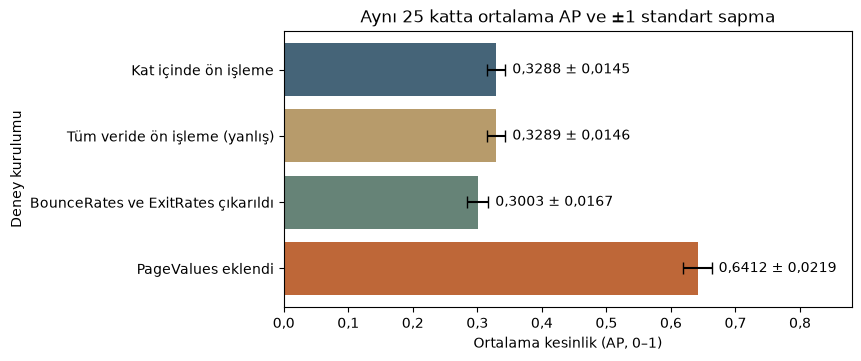

Ürün sayfası görenlerde PageValues = 0: 77.79%


,Oturum,Satın alma,Satın alma oranı
PageValues = 0,9600,370,"3,85%"
PageValues > 0,2730,1538,"56,34%"


In [8]:
correct_score = base_score
global_preprocessing = preprocessing().fit_transform(X)  # Bilerek yanlış
without_rates = preprocessing(numeric_columns=[c for c in numeric if c not in rate_columns])

leakage_scores = {
    "Kat içinde ön işleme": correct_score,
    "Tüm veride ön işleme (yanlış)": fold_scores(LogisticRegression(max_iter=1000), global_preprocessing),
    "BounceRates ve ExitRates çıkarıldı": fold_scores(logistic(without_rates), X.drop(columns=rate_columns)),
    "PageValues eklendi": fold_scores(
        logistic(preprocessing(numeric_columns=numeric + ["PageValues"])), X.assign(PageValues=df_raw["PageValues"])
    ),
}
display(score_summary(leakage_scores))
for name, scores in list(leakage_scores.items())[1:]:
    print(f"{name} — ana modele göre AP farkı:", paired_ap(correct_score, scores))

means = [score["AP"].mean() for score in leakage_scores.values()]
stds = [score["AP"].std() for score in leakage_scores.values()]
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
bars = ax.barh(list(leakage_scores), means, xerr=stds, capsize=4,
               color=["#456478", "#b79b6b", "#668377", "#be6738"])
labels = [f"{mean:.4f} ± {std:.4f}".replace(".", ",") for mean, std in zip(means, stds)]
ax.bar_label(bars, labels=labels, padding=5)
ax.invert_yaxis()
ax.set(xlabel="Ortalama kesinlik (AP, 0–1)", ylabel="Deney kurulumu", xlim=(0, 0.88),
       title="Aynı 25 katta ortalama AP ve ±1 standart sapma")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.1f}".replace(".", ","))
plt.show()

page_values = df_raw["PageValues"]
product_visits = df_raw["ProductRelated"].gt(0)
print(f"Ürün sayfası görenlerde PageValues = 0: {page_values[product_visits].eq(0).mean():.2%}")
page_groups = y.groupby(page_values.gt(0)).agg(["size", "sum", "mean"])
page_groups.index = ["PageValues = 0", "PageValues > 0"]
page_groups.columns = ["Oturum", "Satın alma", "Satın alma oranı"]
display(page_groups.style.format({"Satın alma oranı": "{:.2%}"}, decimal=","))

**Etiketi kullanan ikinci kontrol.** Satın alan oturumları rastgele kopyaladım. Doğru deneyde kopyalar sadece eğitim katından geliyor. Yanlış deneyde kopyalar bölme sınırı gözetmeden bütün pozitif oturumlardan seçiliyor. Her iki durumda da aynı sayıda kopya ürettim, doğrulama satırlarına dokunmadım. Lojistik regresyonda 25 katın tamamını, ek rastgele orman deneyinde ilk tekrarın beş katını kullandım.

In [9]:
buyers = np.flatnonzero(y.eq(1))
train_only, all_buyers = [], []
leaked_share = []
for fold, (train, test) in enumerate(splits):
    rng = np.random.default_rng(SEED + fold)
    train_buyers = train[y.iloc[train].eq(1).to_numpy()]
    count = len(train) - 2 * len(train_buyers)
    inside = rng.choice(train_buyers, size=count, replace=True)
    outside = rng.choice(buyers, size=count, replace=True)
    train_only.append((np.r_[train, inside], test))
    all_buyers.append((np.r_[train, outside], test))

    held_buyers = test[y.iloc[test].eq(1).to_numpy()]
    assert not np.intersect1d(train_only[-1][0], test).size
    leaked_share.append(np.isin(held_buyers, outside).mean())

oversampling_scores = {
    "Sadece eğitimden kopya": fold_scores(onehot, X, cv=train_only),
    "Tüm tablodan kopya (yanlış)": fold_scores(onehot, X, cv=all_buyers),
}
display(score_summary(oversampling_scores))
print("Yanlış − doğru AP farkı:", paired_ap(*oversampling_scores.values()))
print(f"Yanlış deneyde kopyası eğitime giren doğrulama satın almaları: %{100*np.mean(leaked_share):.1f}")


from sklearn.ensemble import RandomForestClassifier

forest = Pipeline([
    ("preprocess", preprocessing()),
    ("model", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)),
])
forest_sampling_scores = {
    "Orman, sadece eğitimden kopya": fold_scores(forest, X, cv=train_only[:5]),
    "Orman, tüm tablodan kopya (yanlış)": fold_scores(forest, X, cv=all_buyers[:5]),
}
display(score_summary(forest_sampling_scores))
print("Ormanda yanlış − doğru AP farkı:", paired_ap(*forest_sampling_scores.values()))


,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Sadece eğitimden kopya,0.3238 ± 0.0136,0.7504 ± 0.0116,0.6836 ± 0.0121,0.3927 ± 0.0111,0.7350 ± 0.0227
Tüm tablodan kopya (yanlış),0.3317 ± 0.0148,0.7579 ± 0.0113,0.6890 ± 0.0130,0.3971 ± 0.0121,0.7471 ± 0.0214


Yanlış − doğru AP farkı: +0.0079 ± 0.0039
Yanlış deneyde kopyası eğitime giren doğrulama satın almaları: %97.4


,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
"Orman, sadece eğitimden kopya",0.3596 ± 0.0132,0.7710 ± 0.0077,0.5741 ± 0.0059,0.2685 ± 0.0141,0.1939 ± 0.0130
"Orman, tüm tablodan kopya (yanlış)",0.9828 ± 0.0039,0.9924 ± 0.0027,0.9559 ± 0.0029,0.8383 ± 0.0078,0.9764 ± 0.0067


Ormanda yanlış − doğru AP farkı: +0.6233 ± 0.0149


**Yorum.** *StandardScaler* ve *OneHotEncoder* etiketi görmüyor. Hatalı kurulumda doğrulama satırlarını kullanıyorlar ama bu veri setinde AP pek değişmedi. Kat içinde AP 0,3288 ± 0,0145, tüm veride 0,3289 ± 0,0146.

Hatalı örneklemede doğrulamadaki satın alma oturumlarının ortalama %97,38'inin bir kopyası eğitime girdi. Yalnız eğitimden kopyalayınca AP 0,3238 ± 0,0136, hatalı örneklemede 0,3317 ± 0,0148 oldu. Eşleştirilmiş AP farkı +0,0079 ± 0,0039. Hangi doğrulama satırlarının kopyalandığını satır indekslerinden kontrol ettim. İlk beş katta rastgele ormanın AP'si yalnız eğitimden kopyalayınca 0,3596 ± 0,0132, doğrulama kopyaları da eğitime girince 0,9828 ± 0,0039 oldu. Ormandaki ağaçlar bir doğrulama satırını eğitimdeki kopyasıyla aynı yaprağa düşürüp kopyanın etiketinden yararlanabiliyor. Lojistik regresyon tek bir doğrusal karar sınırı kurduğu için kopyaların etkisi daha sınırlı kaldı.

*PageValues* ürün sayfası içeren oturumların %77,79'unda sıfır. Satın alma oranı değer 0 iken %3,85, pozitifken %56,34. Bu sayılar hesapta aynı oturumun kullanıldığını kanıtlamıyor. Google'ın tanımında *Page Value*, sayfa ziyaretinden sonra gerçekleşen işlem ve hedef değerinden pay alabiliyor. Kaufman vd.'nin kuralına göre, değeri hesaplayan işlemler tahmin anından önce biliniyor olmalı. CSV'den bunu kontrol edemediğim için sütunu dışarıda bıraktım. Ana modelin AP'si 0,3288. İki çıkış oranı olmadan 0,3003, PageValues eklenince 0,6412 oldu. Hata çubukları katlar arasındaki standart sapma. [Google Analytics, Page Value](https://support.google.com/analytics/answer/1033861?hl=en-uk) · [Kaufman vd. (2012)](https://doi.org/10.1145/2382577.2382579)

### 1.6 Baseline ve ilk model

Dummy modeli her oturuma çoğunluk etiketini veriyor. Lojistik regresyonla aynı 5 kat ve 5 tekrarda karşılaştırdım. Satın alma az görüldüğü için ana ölçütüm AP (ortalama kesinlik).

In [10]:
dummy = Pipeline([
    ("preprocess", preprocessing()),
    ("model", DummyClassifier(strategy="most_frequent")),
])
main_scores = {
    "Dummy · çoğunluk": fold_scores(dummy, X),
    "Lojistik regresyon": correct_score,
}
display(score_summary(main_scores))
print("Lojistik − Dummy, eşleştirilmiş AP farkı:", paired_ap(*main_scores.values()))

# Dış katlar model deneylerinin tamamında aynı satır indekslerini kullanır.
for train, test in splits:
    assert not np.intersect1d(train, test).size
    assert len(train) + len(test) == len(X)
    assert y.iloc[test].nunique() == 2
assert len(splits) == 25 and len(X) == len(df_raw)

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Dummy · çoğunluk,0.1547 ± 0.0002,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Lojistik regresyon,0.3288 ± 0.0145,0.7505 ± 0.0117,0.5119 ± 0.0047,0.0568 ± 0.0179,0.0304 ± 0.0099


Lojistik − Dummy, eşleştirilmiş AP farkı: +0.1741 ± 0.0146


**Yorum.** Dummy hiç satın alma tahmini yapmadı. Lojistik regresyonun AP'si 0,3288 ± 0,0145 çıktı. Varsayılan 0,5 eşikte satın alma duyarlılığı ortalama %3,04 oldu. Yalnız eğitimde aşırı örnekleme yapınca AP 0,3238'e indi, 0,5 eşiğinde duyarlılık %73,50'ye çıktı. Sıralama ölçütü yakın kalsa da aynı eşikte verilen kararlar çok değişti. Bölüm 2'de AP'yi ve eşikteki ölçüleri ayrı raporlayacağım. Aşırı örnekleme denenirse *RandomOverSampler* imblearn *Pipeline* içinde, eğitim katında çalışacak. Bu durumda ilk hücrede *imbalanced-learn* sürümünü de yazdıracağım.

### 1.7 Weka ile bağımsız kontrol

Weka ve Python aynı 12.330 oturumu ve 16 özniteliği kullanıyor. Weka'da ZeroR ve J48'i on katla çalıştırdım. J48'in varsayılan budamasını ve *-U* ile budamasız hâlini karşılaştırdım. Python ağacında yaprak başına en az iki gözlem şartını koruyup yalnızca derinliği sınırladım. [Weka J48 seçenekleri](https://weka.sourceforge.io/doc.stable/weka/classifiers/trees/J48.html)

In [11]:
import os
import shutil
import subprocess
from tempfile import TemporaryDirectory
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, f1_score, recall_score, roc_auc_score,
)

java = shutil.which("java")
if java is None and "google.colab" in sys.modules:
    subprocess.run(["apt-get", "-qq", "update"], check=True, timeout=180)
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-17-jre-headless"],
                   check=True, timeout=240)
    java = shutil.which("java")
if java is None:
    raise RuntimeError("Weka için Java kurup java komutunu PATH'e ekleyin veya Colab kullanın.")

weka_data = X.assign(Revenue=y.astype(bool))
arff_lines = ["@relation online_shoppers"]
for column in weka_data:
    if column in categorical + [target]:
        levels = ",".join(map(str, sorted(weka_data[column].unique())))
        arff_lines.append(f"@attribute {column} {{{levels}}}")
    else:
        arff_lines.append(f"@attribute {column} numeric")

arff_text = ("\n".join(arff_lines + ["@data"]) + "\n" +
             weka_data.to_csv(header=False, index=False, lineterminator="\n"))

maven = "https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka"
jars = {
    "weka-stable/3.8.6/weka-stable-3.8.6.jar":
        "932ea2f342b58fe45736389e9c426d5b5955e610d1f5f6485117f532068915e9",
    "thirdparty/bounce/0.18/bounce-0.18.jar":
        "bffff1505335c02256b7ab2ccffbe4aa4d3ac9fe14c17557809b7c9d99d666ca",
}

weka_commands = {
    "Weka ZeroR": ("rules.ZeroR", []),
    "Weka J48": ("trees.J48", []),
    "Weka J48 budamasız": ("trees.J48", ["-U"]),
}
weka_scores = {}
with TemporaryDirectory(prefix="bil545-") as directory:
    work = Path(directory)
    classpath = []
    for jar, expected_sha in jars.items():
        with urlopen(f"{maven}/{jar}", timeout=45) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected_sha:
            raise ValueError(f"Weka bağımlılığının SHA-256 değeri eşleşmedi: {jar}")
        jar_file = work / Path(jar).name
        jar_file.write_bytes(content)
        classpath.append(str(jar_file))

    arff = work / "online_shoppers.arff"
    arff.write_text(arff_text, encoding="ascii")

    for name, (classifier, options) in weka_commands.items():
        predictions = work / "predictions.csv"
        csv_options = (
            'weka.classifiers.evaluation.output.prediction.CSV '
            f'-file "{predictions.as_posix()}" -suppress -distribution -decimals 12'
        )
        command = [
            java, "-Djava.awt.headless=true", "-Dfile.encoding=UTF-8",
            "-Duser.language=en", "-Duser.country=US", "-cp", os.pathsep.join(classpath),
            f"weka.classifiers.{classifier}", "-t", str(arff), "-c", "last",
            "-x", "10", "-s", str(SEED), "-v", "-o", *options,
        ]
        # Weka CLI, özet ve satır tahminlerini iki farklı çıktı kipinde verir.
        java_options = {"cwd": work, "capture_output": True, "text": True,
                        "encoding": "utf-8", "errors": "replace", "timeout": 90}
        summary = subprocess.run(command, **java_options)
        run = subprocess.run(command + ["-classifications", csv_options], **java_options)
        if summary.returncode or "Stratified cross-validation" not in summary.stdout:
            raise RuntimeError(f"{name} (özet)\n{summary.stdout}\n{summary.stderr}")
        if run.returncode or not predictions.is_file():
            raise RuntimeError(f"{name} (tahminler)\n{run.stdout}\n{run.stderr}")
        report = summary.stdout[summary.stdout.index("==="):].strip()
        print(f"\n{name} · Weka 3.8.6\n{report}")

        pred = pd.read_csv(
            predictions, header=None, skiprows=1, usecols=[0, 1, 2, 5],
        )
        pred.columns = ["instance", "actual", "predicted", "positive_probability"]
        pred["fold"] = pred["instance"].eq(1).cumsum()
        assert pred["fold"].nunique() == 10 and len(pred) == len(y)
        actual_all = pred["actual"].str.endswith(":True")
        assert actual_all.sum() == y.sum()
        metrics = []
        for _, group in pred.groupby("fold", sort=True):
            actual = group["actual"].str.endswith(":True")
            predicted = group["predicted"].str.endswith(":True")
            probability = group["positive_probability"].astype(str).str.lstrip("*").astype(float)
            metrics.append({
                "AP": average_precision_score(actual, probability),
                "ROC AUC": roc_auc_score(actual, probability),
                "Dengeli doğruluk": balanced_accuracy_score(actual, predicted),
                "F1": f1_score(actual, predicted, zero_division=0),
                "Duyarlılık": recall_score(actual, predicted),
            })
        weka_scores[name] = pd.DataFrame(metrics)
        predictions.unlink()

python_10fold = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
comparison = {
    "Python Dummy": fold_scores(dummy, X, cv=python_10fold),
    "Python lojistik": fold_scores(onehot, X, cv=python_10fold),
    **weka_scores,
}
tree_ap = {}
for depth, name in [(None, "Python ağacı, sınır yok"), (6, "Python ağacı, derinlik 6")]:
    model = Pipeline([
        ("preprocess", preprocessing()),
        ("model", DecisionTreeClassifier(
            criterion="entropy", min_samples_leaf=2, max_depth=depth, random_state=SEED
        )),
    ])
    scores = cross_validate(model, X, y, cv=python_10fold, scoring=SCORING,
                            return_train_score=True, error_score="raise")
    comparison[name] = pd.DataFrame({metric: scores[f"test_{metric}"] for metric in SCORING})
    tree_ap[name] = pd.DataFrame({
        "Eğitim AP": scores["train_AP"],
        "Doğrulama AP": scores["test_AP"],
    })

display(score_summary(comparison))
display(score_summary(tree_ap))



Weka ZeroR · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances       10422               84.5255 %
Incorrectly Classified Instances      1908               15.4745 %
Kappa statistic                          0     
Mean absolute error                      0.2616
Root mean squared error                  0.3617
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances            12330     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1.000    1.000    0.845      1.000    0.916      ?        0.500     0.845     False
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.155     True
Weighted Avg.    0.845    0.845    ?          0.845    ?          ?        0.500     0.738     


=== Confusion Matrix ===

     a     b   <-- classified as
 10422     0 | 


Weka J48 · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances       10421               84.5174 %
Incorrectly Classified Instances      1909               15.4826 %
Kappa statistic                          0.1162
Mean absolute error                      0.2355
Root mean squared error                  0.3539
Relative absolute error                 90.0207 %
Root relative squared error             97.8422 %
Total Number of Instances            12330     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0.982    0.905    0.856      0.982    0.915      0.166    0.693     0.908     False
                 0.095    0.018    0.499      0.095    0.160      0.166    0.693     0.294     True
Weighted Avg.    0.845    0.767    0.800      0.845    0.798      0.166    0.693     0.813     


=== Confusion Matrix ===

     a     b   <-- classified as
 10239   183 |   


Weka J48 budamasız · Weka 3.8.6
=== Stratified cross-validation ===

Correctly Classified Instances        9839               79.7972 %
Incorrectly Classified Instances      2491               20.2028 %
Kappa statistic                          0.1654
Mean absolute error                      0.2235
Root mean squared error                  0.4232
Relative absolute error                 85.4046 %
Root relative squared error            117.0095 %
Total Number of Instances            12330     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0.897    0.744    0.868      0.897    0.882      0.166    0.600     0.867     False
                 0.256    0.103    0.313      0.256    0.282      0.166    0.600     0.237     True
Weighted Avg.    0.798    0.645    0.782      0.798    0.789      0.166    0.600     0.769     


=== Confusion Matrix ===

    a    b   <-- classified as
 9351 107

,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Python Dummy,0.1547 ± 0.0003,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Python lojistik,0.3319 ± 0.0151,0.7511 ± 0.0162,0.5130 ± 0.0046,0.0607 ± 0.0165,0.0325 ± 0.0091
Weka ZeroR,0.1547 ± 0.0003,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Weka J48,0.2723 ± 0.0331,0.6866 ± 0.0286,0.5389 ± 0.0151,0.1580 ± 0.0472,0.0954 ± 0.0348
Weka J48 budamasız,0.2386 ± 0.0207,0.5994 ± 0.0336,0.5765 ± 0.0204,0.2809 ± 0.0378,0.2557 ± 0.0402
"Python ağacı, sınır yok",0.1989 ± 0.0072,0.5862 ± 0.0113,0.5706 ± 0.0109,0.2728 ± 0.0192,0.2636 ± 0.0221
"Python ağacı, derinlik 6",0.3398 ± 0.0220,0.7540 ± 0.0111,0.5384 ± 0.0120,0.1578 ± 0.0405,0.0949 ± 0.0263


,Eğitim AP,Doğrulama AP
"Python ağacı, sınır yok",0.9770 ± 0.0014,0.1989 ± 0.0072
"Python ağacı, derinlik 6",0.3917 ± 0.0058,0.3398 ± 0.0220


**Yorum.** ZeroR ve Dummy satın alma tahmini yapmadı ve her ikisinin AP'si 0,1547 ± 0,0003. Weka'nın AP'sini modelin kat tahminlerinden Python'la aynı şekilde hesapladım.

J48'in AP'si varsayılan budamayla 0,2723 ± 0,0331, budama kapalıyken 0,2386 ± 0,0207 oldu. Derinlik sınırı olmayan Python ağacında eğitim AP'si 0,9770, doğrulama AP'si 0,1989. Bu fark aşırı öğrenmeyle uyumlu. Derinliği 6 ile sınırladığımda doğrulama AP'si 0,3398 oldu.

Derinlik 6, 10 katlı ön denemede bakılan dört ayar arasından seçildi. Burada aşırı öğrenmeyi göstermek için örnek olarak kullandım. Ayar sonuçlara bakılarak seçildiği için 0,3398 iyimser olabilir. Bölüm 2.3'te iç içe çapraz doğrulama kullanacağım. Derinliği iç katlarda seçeceğim, AP'yi dış katlarda ölçeceğim.

Python CART, Weka J48 ise C4.5 kullanıyor. Weka içindeki iki koşul budamanın etkisini gösteriyor. Python ile Weka arasındaki farkta algoritma, kategorilerin işlenişi ve katların dağılımı da rol oynayabilir.

**Weka Explorer'da denemek için**

1. 1.7 hücresi bittikten sonra ARFF dosyasını yeni bir hücrede oluşturun.

       Path("online_shoppers_bolum1.arff").write_text(arff_text, encoding="ascii")

2. Weka'da **Preprocess → Open file** ile dosyayı açın.
3. **Classify** bölümünde hedef olarak *Revenue*, değerlendirme olarak **Cross-validation (10 kat)** seçin. **More options** altında seed 42 olsun. ZeroR ve J48'i ayrı ayrı çalıştırın. Budamasız karşılaştırma için J48 ayarlarında *unpruned* seçeneğini açın.

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme

**Okuma notu.** Dietterich (1998), aynı problemde iki sınıflandırma yöntemini karşılaştırmak için beş testi inceliyor. Eğitim örnekleri tekrar kullanıldığında skorlar bağımsız olmadığı için bazı t-testlerinin gerçekte fark yokken sıkça fark bulduğunu gösteriyor. McNemar testi aynı test örneklerinde iki modelin farklı sonuç verdiği durumlara bakıyor ve deneylerde düşük Tip I hata veriyor. 5×2 çapraz doğrulama testi ise eğitim kümesi değiştiğinde farkın nasıl değiştiğini de hesaba katıyor. [Dietterich (1998)](https://doi.org/10.1162/089976698300017197)

### 2.1 Model karşılaştırması

Bölüm 1'deki 16 öznitelikle ve 12.330 oturumla devam ettim. McNemar testi için oturumların %20'sini sınıf oranını koruyarak ayırdım. Kalan %80'de bütün modelleri aynı 5 kat ve 5 tekrarla karşılaştırdım.

Oturumların yaklaşık %15,5'i satın almayla bitiyor. Ana ölçüt olarak ortalama kesinliği (AP) kullandım. AP, satın alma olasılıklarının sıralamasında kesinlik ve duyarlılığı birlikte değerlendiriyor. F1 ve duyarlılık ise modelin varsayılan karar eşiğinde ne yaptığını gösteriyor.

Bölüm 1'deki ön işlemeyi her modelin hattına ekledim. Ölçekleme özellikle k-NN için gerekli. Ağaç derinliği iç katlarda AP'ye göre seçiliyor. Diğer modeller için tabloda kullanılan ayarlar sabit, sınıf oranına da dokunmadım.

Aşağıdaki yorum ve tablolar kayıtlı yerel çalıştırmadan (scikit-learn 1.9.1). Defteri Colab'da scikit-learn 1.6.1 ile de baştan sona çalıştırdım.

Geliştirme: 9864 oturum · Test: 2466 oturum


,AP,ROC AUC,Dengeli doğruluk,F1,Duyarlılık
Rastgele orman,"0,3820 ± 0,0211","0,7823 ± 0,0105","0,5147 ± 0,0045","0,0641 ± 0,0171","0,0341 ± 0,0095"
Gradyan artırma,"0,3730 ± 0,0191","0,7827 ± 0,0113","0,5405 ± 0,0065","0,1648 ± 0,0200","0,0987 ± 0,0136"
Lojistik regresyon,"0,3259 ± 0,0217","0,7523 ± 0,0146","0,5102 ± 0,0035","0,0509 ± 0,0150","0,0273 ± 0,0087"
Karar ağacı,"0,3186 ± 0,0181","0,7416 ± 0,0154","0,5387 ± 0,0199","0,1574 ± 0,0697","0,0993 ± 0,0495"
k-NN,"0,2788 ± 0,0168","0,7135 ± 0,0140","0,5125 ± 0,0039","0,0615 ± 0,0130","0,0332 ± 0,0072"
Dummy,"0,1547 ± 0,0002","0,5000 ± 0,0000","0,5000 ± 0,0000","0,0000 ± 0,0000","0,0000 ± 0,0000"


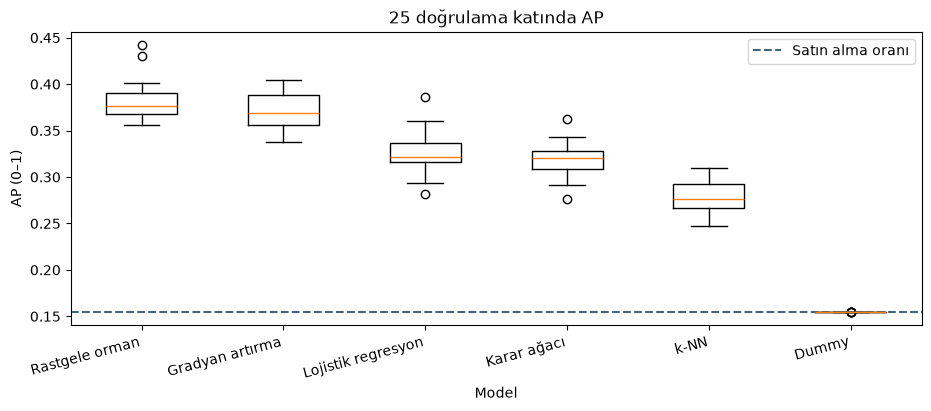

In [12]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
dev_splits = list(outer_cv.split(X_dev, y_dev))
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Geliştirme: {len(y_dev)} oturum · Test: {len(y_test)} oturum")

def model_pipeline(model):
    preprocess = preprocessing().set_params(sparse_threshold=0)
    return Pipeline([("preprocess", preprocess), ("model", model)])

tree_pipe = model_pipeline(DecisionTreeClassifier(
    criterion="entropy", min_samples_leaf=2, random_state=SEED
))
depth_grid = {"model__max_depth": [2, 4, 6, 8, None]}
tree_search = GridSearchCV(
    tree_pipe, depth_grid, scoring="average_precision", cv=inner_cv, error_score="raise"
)

models = {
    "Dummy": model_pipeline(DummyClassifier(strategy="most_frequent")),
    "Lojistik regresyon": model_pipeline(LogisticRegression(max_iter=1000)),
    "Karar ağacı": tree_search,
    "k-NN": model_pipeline(KNeighborsClassifier(n_neighbors=21)),
    "Rastgele orman": model_pipeline(RandomForestClassifier(
        n_estimators=100, min_samples_leaf=5, n_jobs=2, random_state=SEED
    )),
    "Gradyan artırma": model_pipeline(HistGradientBoostingClassifier(
        max_iter=100, max_leaf_nodes=15, early_stopping=False, random_state=SEED
    )),
}

model_scores = {}
with threadpoolctl.threadpool_limits(limits=2):
    for name, estimator in models.items():
        result = cross_validate(
            estimator, X_dev, y_dev, cv=dev_splits, scoring=SCORING, error_score="raise"
        )
        model_scores[name] = pd.DataFrame({key: result[f"test_{key}"] for key in SCORING})

ranking = sorted(model_scores, key=lambda name: -model_scores[name]["AP"].mean())
display(score_summary({name: model_scores[name] for name in ranking}).map(
    lambda value: value.replace(".", ",")
))

fig, ax = plt.subplots(figsize=(9.2, 4), layout="constrained")
ax.boxplot([model_scores[name]["AP"] for name in ranking])
ax.set_xticks(range(1, len(ranking) + 1), ranking, rotation=15, ha="right")
ax.axhline(y_dev.mean(), color="#456478", linestyle="--", label="Satın alma oranı")
ax.set(title="25 doğrulama katında AP", xlabel="Model", ylabel="AP (0–1)")
ax.legend()
plt.show()

**Yorum.** Rastgele orman 0,3820 ± 0,0211 AP ile ilk sırada. Gradyan artırmanın AP'si 0,3730 ± 0,0191 ve kutu grafiğinde iki modelin kat skorları örtüşüyor. Kesikli çizgi, Dummy'nin de yaklaşık olarak verdiği satın alma oranı. Orman daha iyi sıralama yaptı ama varsayılan eşikte satın alanların ortalama %3,4'ünü yakaladı. Gradyan artırmada bu oran %9,9. AP ile eşikte verilen kararın aynı şeyi ölçmediği burada da görünüyor.

Colab'da ormanın AP'si aynı kaldı, gradyan artırma 0,3744 ± 0,0214 AP aldı. Orman ilk sırada kaldı.

### 2.2 Karar ağacının yorumu

Ağacın hangi sütunlarla başladığını görmek için derinliği geliştirme verisinde seçip ağacı aynı veride eğittim. Aşağıda kök ve hemen altındaki bölmeler var.

In [13]:
from sklearn.tree import export_text

# 2.3'teki karşılaştırma için geliştirme katlarında yapılan aramayı da saklıyorum.
with threadpoolctl.threadpool_limits(limits=2):
    dev_tree = clone(tree_search).set_params(cv=dev_splits).fit(X_dev, y_dev)
tree_model = dev_tree.best_estimator_
tree_features = tree_model["preprocess"].get_feature_names_out()
print("Seçilen derinlik:", dev_tree.best_params_["model__max_depth"])
print(export_text(tree_model["model"], feature_names=list(tree_features), max_depth=1))

tree = tree_model["model"].tree_
scaler = tree_model["preprocess"].named_transformers_["sayisal"]["scale"]
nodes = [0, tree.children_left[0], tree.children_right[0]]
rules = []
for node in nodes:
    col = tree.feature[node]
    if col < 0:
        continue
    column = tree_features[col]
    threshold = tree.threshold[node]
    if column.startswith("sayisal__"):
        threshold = threshold * scaler.scale_[col] + scaler.mean_[col]
    rules.append({
        "Düğüm": node, "Öznitelik": column.split("__", 1)[1],
        "Eşik (ham ölçekte)": threshold,
    })
display(pd.DataFrame(rules).style.format({"Eşik (ham ölçekte)": "{:.3f}"}, decimal=","))

Seçilen derinlik: 6
|--- sayisal__ExitRates <= -0.07
|   |--- sayisal__ProductRelated_Duration <= -0.39
|   |   |--- truncated branch of depth 5
|   |--- sayisal__ProductRelated_Duration >  -0.39
|   |   |--- truncated branch of depth 5
|--- sayisal__ExitRates >  -0.07
|   |--- sayisal__ExitRates <= 0.67
|   |   |--- truncated branch of depth 5
|   |--- sayisal__ExitRates >  0.67
|   |   |--- truncated branch of depth 5



,Düğüm,Öznitelik,Eşik (ham ölçekte)
0,0,ExitRates,"0,040"
1,1,ProductRelated_Duration,"442,750"
2,60,ExitRates,"0,076"


**Yorum.** Ağaç önce *ExitRates* ile yaklaşık 0,040'ta bölüyor. Düşük çıkış oranlı tarafta ürün sayfalarında geçirilen toplam süreye bakıyor (eşik 442,75). Diğer tarafta çıkış oranıyla tekrar bölüyor (yaklaşık 0,076). *ExitRates*, gezilen sayfaların son sayfa olma oranından geliyor. Düşük çıkış oranlı tarafta süre eşiği kısa bakışlarla daha uzun ürün incelemelerini ayırıyor. Bu eşikler bu örneklemde öğrenildi ve satın almanın nedenini göstermez.

### 2.3 Optimist yanlılık

Aynı karar ağacı için iki AP hesabı yaptım. İlkinde 25 kat hem derinliği seçmek hem de seçilen ayarı puanlamak için kullanılıyor. İkincisinde derinlik dış katın eğitim parçasında 5 iç katla seçiliyor. 2.1'deki ağaç AP'si bu ikinci hesaptan geliyor.

In [14]:
best_index = dev_tree.best_index_
nested_ap = model_scores["Karar ağacı"]["AP"]
selected_ap = pd.Series([
    dev_tree.cv_results_[f"split{i}_test_score"][best_index] for i in range(len(dev_splits))
])
search_comparison = {
    "Seçimde kullanılan katlar": pd.DataFrame({"AP": selected_ap}),
    "İç içe ÇD, dış katlar": pd.DataFrame({"AP": nested_ap}),
}
display(score_summary(search_comparison).map(lambda value: value.replace(".", ",")))
print("GridSearchCV.best_score_:", f"{dev_tree.best_score_:.4f}".replace(".", ","))
print("Eşleştirilmiş fark (ilk satır − ikinci satır):",
      paired_ap(search_comparison["İç içe ÇD, dış katlar"], search_comparison["Seçimde kullanılan katlar"])
      .replace(".", ","))

,AP
Seçimde kullanılan katlar,"0,3207 ± 0,0178"
"İç içe ÇD, dış katlar","0,3186 ± 0,0181"


GridSearchCV.best_score_: 0,3207
Eşleştirilmiş fark (ilk satır − ikinci satır): +0,0020 ± 0,0102


**Yorum.** Geliştirme katlarında seçilen derinlik 6'nın AP'si 0,3207. Her dış katın derinliğini kendi iç katlarında seçince AP 0,3186 oldu. Eşleştirilmiş fark +0,0020 ± 0,0102. Bu taramada iyimserlik küçük çıktı. Derinlik seçiminin sonucunu değerlendirirken dış kat ölçümünü kullanıyorum.

### 2.4 İstatistiksel test

AP sıralamasındaki ilk iki modeli geliştirme verisinde eğittim. McNemar testini ayırdığım oturumlarda, modellerin varsayılan karar eşiğindeki doğru ve yanlış tahminleri üzerinden yaptım. Test çift taraflı ve anlamlılık düzeyi 0,05. AP farkını doğrudan sınamıyor.

In [15]:
from scipy.stats import binomtest

first, second = ranking[:2]
with threadpoolctl.threadpool_limits(limits=2):
    fitted = {
        name: tree_model if name == "Karar ağacı" else clone(models[name]).fit(X_dev, y_dev)
        for name in (first, second)
    }
    correct_first = fitted[first].predict(X_test) == y_test.to_numpy()
    correct_second = fitted[second].predict(X_test) == y_test.to_numpy()
b = int((correct_first & ~correct_second).sum())
c = int((~correct_first & correct_second).sum())
table = [
    [int((correct_first & correct_second).sum()), b],
    [c, int((~correct_first & ~correct_second).sum())],
]
display(pd.DataFrame(
    table,
    index=[f"{first} doğru", f"{first} yanlış"],
    columns=[f"{second} doğru", f"{second} yanlış"],
))
# Kesin McNemar, yalnızca b + c uyuşmaz çift üzerinde binom testi.
mcnemar_p = binomtest(b, b + c, p=0.5).pvalue if b + c else 1.0
print(f"Uyuşmaz çiftler: {b} ve {c} · p = {mcnemar_p:.4f}".replace(".", ","))

,Gradyan artırma doğru,Gradyan artırma yanlış
Rastgele orman doğru,2059,29
Rastgele orman yanlış,26,352


Uyuşmaz çiftler: 29 ve 26 · p = 0,7877


**Yorum.** 2.466 test oturumunun 29'unda yalnız orman, 26'sında yalnız gradyan artırma doğru bildi. p = 0,7877. Bu örnekte iki modelin hata oranı arasında anlamlı fark bulamadım. Bu yorum varsayılan eşikteki hata oranıyla sınırlı. Bölüm 1'in veri incelemesi tüm CSV'yi kapsıyor. Bu test oturumlarını Bölüm 2'deki model seçimi dışında tuttum.

Colab'da uyuşmaz çift sayıları 27 ve 30, p = 0,7914 çıktı. Testin yorumu aynı kaldı.

### 2.5 Proje 2'ye aktarılacak model ve çıktılar

Modeli 25 geliştirme katındaki ortalama AP'ye göre seçtim. Aktarılacak hattı testten sonra bütün oturumlarla tekrar eğittim. Bu son dosya, McNemar testinde kullanılan modelden daha fazla veriyle eğitildi. Proje 2'de yeni bir başarı ölçümü yaparken ilgili katlarda hattı yeniden eğitmek gerekiyor.

In [16]:
import json

winner = first
winner_pipeline = fitted[winner]
with threadpoolctl.threadpool_limits(limits=2):
    final_pipeline = clone(winner_pipeline).fit(X, y)

output_dir = Path("p1_ciktilar")
output_dir.mkdir(exist_ok=True)
csv_path = output_dir / "p1_temiz_veri.csv"
model_path = output_dir / "p1_hat.joblib"
X.assign(**{target: y}).to_csv(csv_path, index=False)
joblib.dump(final_pipeline, model_path, compress=3)

protocol = {
    "model": winner,
    "model_ayarlari": final_pipeline["model"].get_params(),
    "seed": SEED,
    "ana_olcut": "average_precision",
    "gelistirme": {"kat": 5, "tekrar": 5, "test_orani": 0.20},
    "agac_ic_kat": 5,
    "ozellikler": X.columns.tolist(),
    "hedef": target,
    "girdi_sha256": hashlib.sha256(csv_bytes).hexdigest(),
    "python": sys.version.split()[0],
    "surumler": {
        lib.__name__: lib.__version__ for lib in (np, pd, scipy, sklearn, joblib, threadpoolctl)
    },
}
(output_dir / "p1_protokol.json").write_text(
    json.dumps(protocol, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)

loaded_data = pd.read_csv(csv_path)
loaded_model = joblib.load(model_path)
assert loaded_data.columns.tolist() == [*X.columns, target]
np.testing.assert_array_equal(loaded_data[target], y)
with threadpoolctl.threadpool_limits(limits=2):
    np.testing.assert_allclose(
        loaded_model.predict_proba(loaded_data[X.columns]), final_pipeline.predict_proba(X)
    )
print("Seçilen model:", winner)
print("Kaydedilen dosyalar:", csv_path.name, model_path.name, "p1_protokol.json")
print(f"Tekrar yüklemede {len(y)} oturumun olasılıkları eşleşti.")

Seçilen model: Rastgele orman
Kaydedilen dosyalar: p1_temiz_veri.csv p1_hat.joblib p1_protokol.json
Tekrar yüklemede 12330 oturumun olasılıkları eşleşti.


**Yorum.** Aktarım için rastgele ormanı seçtim. Gerekçem geliştirme katlarında en yüksek AP'yi alması. 0,5 eşikte duyarlılığı düşük olduğu için satın alma uyarısı vermek üzere eşik seçmek ayrı bir çalışma. Temiz CSV'de 16 girdi ve *Revenue* var. Modelle birlikte ön işleme hattını da kaydettim. *p1_protokol.json* dosyasında veri özeti, bölme ayarları ve kullanılan sürümler var.

## Varsayım defteri

- UCI'daki 12.330 satırı tuttum. Aynı sayfa özeti farklı oturumlardan gelebiliyor.
- Kaufman vd.'nin öğrenme ve tahmin bilgisini ayırma ilkesini kullandım. *PageValues* hesabına hangi dönemin işlemlerinin girdiği belli olmadığı için sütunu çıkardım. Katın ölçek ve kodlama ayarlarını eğitimden aldım.
- *BounceRates* ve *ExitRates* oturum sonu modelinde var. Bu oranları geçmişten dondurulmuş ölçüler olarak doğrulayamadığım için ileri tarihli bir kullanım iddiasında bulunmuyorum.
- Sıfır süreleri ana veride tuttum. Olası eksik saydığım ürün ve bilgi sayfası sürelerini ayrı bir deneyde medyanla doldurdum.
- Nadir trafik türleri için 20 gözlem, hedef kodlama için *smooth=10* kullandım. Bu ayarları skor tarayarak seçmedim.
- Ana ölçüt AP. 5 katlı doğrulamayı 5 kez tekrarladım. Kullanıcı kimliği ve tam tarih olmadığı için kullanıcıya göre veya ileri zamana doğru bölme yapamadım.
- Bölüm 2'de AP sıralamasını geliştirme verisindeki 25 kattan aldım. Ağacın derinliğini iç katlarda seçtim. F1 ve duyarlılık için modellerin varsayılan karar eşiğini kullandım.
- Dietterich (1998) doğrultusunda McNemar için aynı test oturumlarında eşleşen kararları kullandım. Bu oturumlar Bölüm 2'deki seçimden önce ayrıldı. Bölüm 1'in veri incelemesi bütün CSV'yi kapsıyor.

## Katkı beyanı

Konu 9.5'i ve UCI veri setini ben seçtim. Tek çalıştığım için grup içindeki payım %100. Bölüm 1'de veri inceleme, sızıntı deneyleri ve Weka kontrolü; Bölüm 2'de model karşılaştırması, ağaç yorumu, iç içe doğrulama, McNemar ve çıktıların hazırlanması benim sorumluluğumdaydı. Sunumda AP'yi neden seçtiğimi ve 2.3–2.4 sonuçlarını anlatmayı planlıyorum.

## Yapay zekâ beyanı

Kodları ve açıklamaları hazırlarken OpenAI Codex'ten yardım aldım. Codex deneyleri çalıştırmak ve çıktıları kontrol etmek için de kullanıldı.

## Kaynaklar

- Sakar, C. O. ve Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [Veri kümesi ve lisans](https://doi.org/10.24432/C5F88Q).
- Sakar, C. O., Polat, S. O., Katircioglu, M. ve Kastro, Y. (2019). Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications, 31*, 6893–6908. [Makale](https://doi.org/10.1007/s00521-018-3523-0).
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD, 6*(4), 15. [Makale](https://doi.org/10.1145/2382577.2382579).
- scikit-learn. [TargetEncoder ve kat dışı kodlama](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html), [average_precision_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- University of Waikato. [Weka 3.8.6](https://github.com/Waikato/weka-3.8/blob/master/wekadocs/README), [komut satırı örnekleri](https://waikato.github.io/weka-wiki/primer/).
- Katırcıoğlu, M. A. (2018). *Predicting commercial intent of online consumers using machine learning techniques*, s. 18 ve 32. [Yüksek lisans tezi](https://acikerisim.bahcesehir.edu.tr/server/api/core/bitstreams/039f6b43-b844-41b8-a8e7-6b92ed5bdd39/content).
- Google Analytics. [Universal Analytics ilişkilendirme ve Page Value](https://support.google.com/analytics/answer/1033861?hl=en-uk), [tek istekli oturumlar](https://support.google.com/analytics/answer/9264222?hl=en).
- U.S. EPA. [Google Analytics ölçümleri sözlüğü](https://www.epa.gov/sites/production/files/documents/glossary_of_metrics_used_in_google_analytics.pdf).
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923. [Makale](https://doi.org/10.1162/089976698300017197).